# GLIMS inventory by region

How the selected glaciers (notebook 01) spread across regions and the map, compared with the subsets
actually trained on (`filtered_training_data_summer_months.csv`) and run through inference (the
250-per-region selection). The world outline is Natural Earth's, fetched over the network.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from glacierview import config, glims

WORLD = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"

glaciers = glims.add_region_rollup(glims.read_selection())
trained = pd.read_csv(config.processed_metadata_dir(config.TRAINING_DATA_LABEL)
                      / "filtered_training_data_summer_months.csv")["glims_id"]
inference = pd.read_csv(config.inference_sample_path(250))["glims_id"]
subsets = {
    "selected": glaciers,
    "trained on": glaciers[glaciers["glac_id"].isin(trained)],
    "inference": glaciers[glaciers["glac_id"].isin(inference)],
}
pd.DataFrame({name: df["geog_area_rollup"].value_counts(dropna=False)
              for name, df in subsets.items()})

,selected,trained on,inference
geog_area_rollup,,,
Asia,12625,4900.0,250.0
Caucausus,255,74.0,74.0
Europe,602,199.0,199.0
North America,3704,1554.0,251.0
Oceania,35,NaN,NaN
South America,872,447.0,250.0


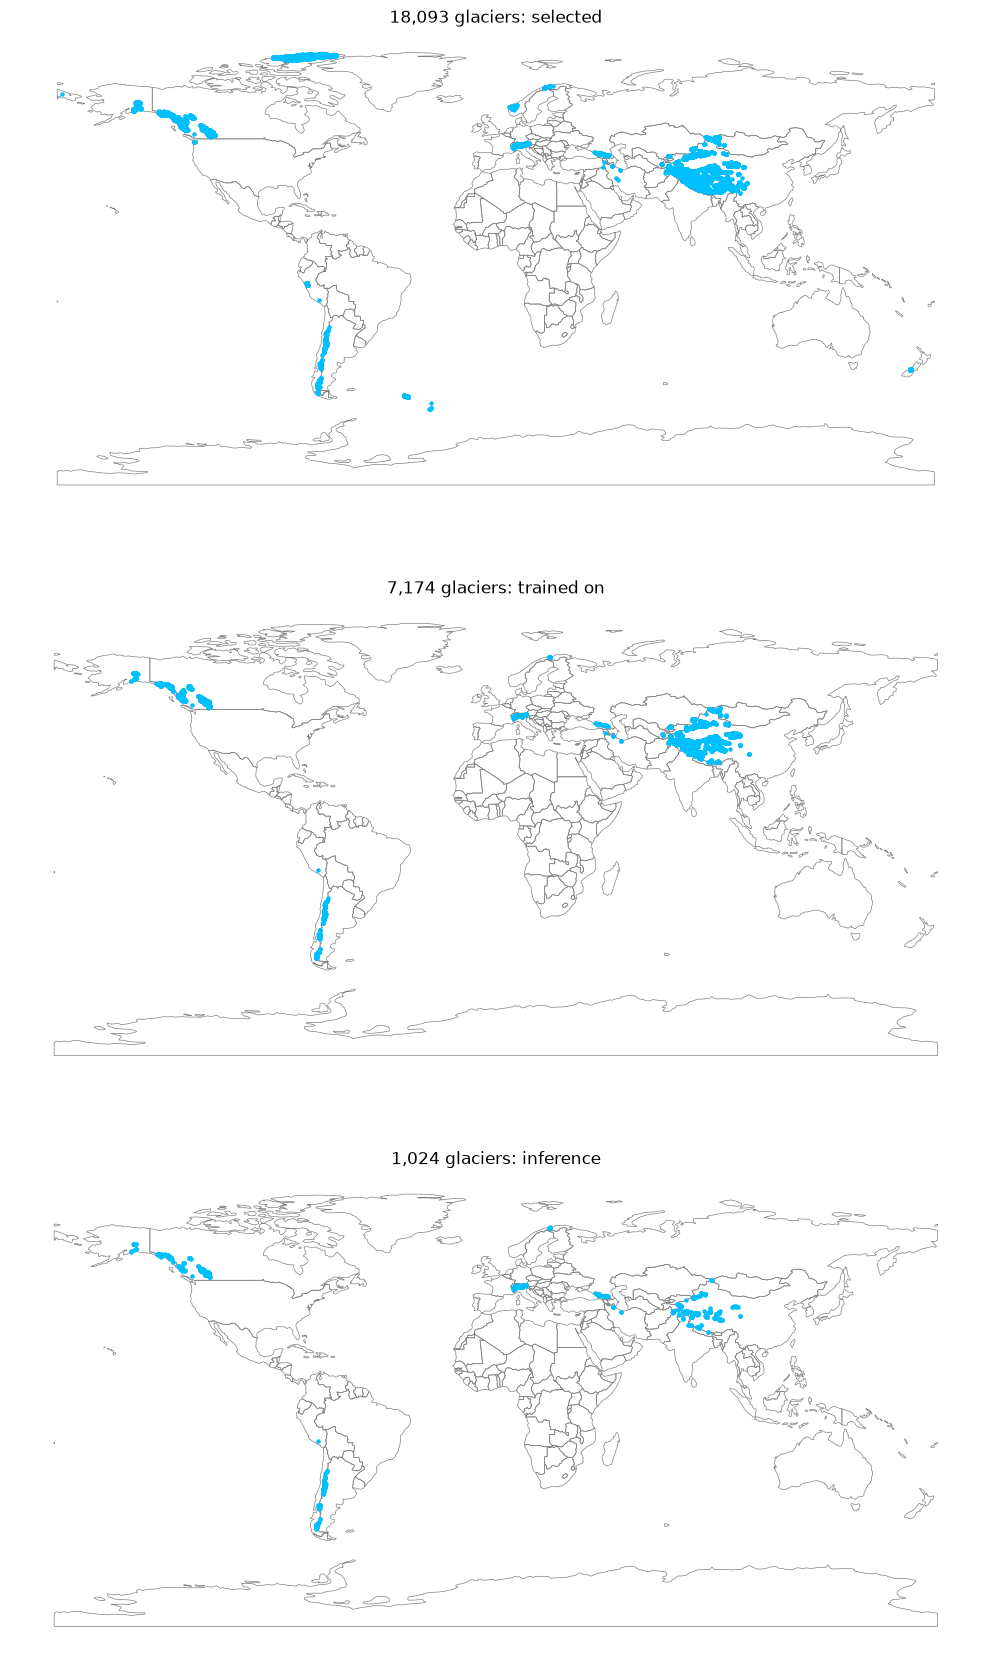

In [2]:
world = gpd.read_file(WORLD)
fig, axs = plt.subplots(len(subsets), 1, figsize=(15, 7 * len(subsets)))
for ax, (name, df) in zip(axs, subsets.items(), strict=True):
    world.plot(ax=ax, facecolor="none", edgecolor="grey", linewidth=0.5)
    df.geometry.representative_point().plot(ax=ax, color="deepskyblue", markersize=5)
    ax.set_title(f"{len(df):,} glaciers: {name}")
    ax.set_axis_off()
plt.show()